# Métodos Numéricos · AUTOGEST
## Regresión Lineal (Mínimos Cuadrados) + Interpolación de Lagrange

**Proyecto:** AUTOGEST – Siniestralidad Vial · Ibagué, Colombia  
**Asignatura:** Métodos Numéricos  
**Universidad:** UNIMINUTO Ibagué · 2026-2  

---

### ¿Qué son los individuos / observaciones?
Cada observación representa el **promedio anual de accidentes registrados en Ibagué** para un año calendario específico (2014–2026). Es una **medición real del sistema vial** urbano de la ciudad.

| Elemento | Descripción |
|---|---|
| **Individuo** | Un año calendario (ej: 2020) |
| **Qué mide** | Promedio anual de accidentes de tránsito registrados |
| **Fuente** | Dataset AUTOGEST – 507 registros mensuales (2014–2026) |


## 1. Configuración del Entorno

In [1]:
import sys
import os

# Agregar raíz del proyecto al path
ruta_proyecto = os.path.abspath(os.path.join(os.getcwd(), '..'))
if ruta_proyecto not in sys.path:
    sys.path.insert(0, ruta_proyecto)

print(f"Ruta del proyecto: {ruta_proyecto}")
print("Python:", sys.version)

Ruta del proyecto: c:\Users\Gilary Gacha\Desktop\autogest
Python: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib

from src.metodos_numericos import (
    RegresionLineal,
    InterpolacionLagrange,
    generar_figuras,
    ejecutar_completo,
    DATOS_ANUALES,
    NODOS_LAGRANGE,
)

print("✅ Módulo metodos_numericos importado correctamente")
print(f"   Datos disponibles: {len(DATOS_ANUALES['X'])} años ({DATOS_ANUALES['X'][0]}–{DATOS_ANUALES['X'][-1]})")

✅ Módulo metodos_numericos importado correctamente
   Datos disponibles: 13 años (2014–2026)


## 2. Definición de Variables

Siguiendo las instrucciones del profesor:
> *"Que elijan dos variables que sean cuantitativas... deben decir cuál es la dependiente y la independiente"*

| Rol | Variable | Eje | Justificación |
|---|---|---|---|
| **Independiente (X)** | `AÑO` | Eje X | Variable de tiempo — avanza independientemente |
| **Dependiente (Y)** | `ACCIDENTES_REGISTRADOS` | Eje Y | Depende del tiempo: **¿a medida que pasan los años, aumentan o disminuyen los accidentes?** |

> *Analogía del profesor: "a medida que va pasando el tiempo, ¿va a aumentar la temperatura o bajar la temperatura? La temperatura depende del tiempo."*  
> → En nuestro caso: **los accidentes dependen del tiempo (año).**

## 3. Datos del Proyecto — Tabla de Observaciones

In [3]:
# Crear DataFrame con los datos
X = DATOS_ANUALES["X"]
Y = DATOS_ANUALES["Y"]

df_datos = pd.DataFrame({
    "AÑO (X - Independiente)": X,
    "ACCIDENTES REGISTRADOS (Y - Dependiente)": Y,
    "Observación": [f"Promedio de accidentes en {a}" for a in X]
})

print(f"Total de observaciones: {len(X)}")
print(f"Rango X: [{min(X)}, {max(X)}]  — DATO MÍNIMO y MÁXIMO incluidos ✅")
print(f"Mínimo Y: {min(Y):.2f} (año {X[Y.index(min(Y))]})")
print(f"Máximo Y: {max(Y):.2f} (año {X[Y.index(max(Y))]})")
print()
print(df_datos.to_string(index=False))

Total de observaciones: 13
Rango X: [2014, 2026]  — DATO MÍNIMO y MÁXIMO incluidos ✅
Mínimo Y: 259.98 (año 2020)
Máximo Y: 2106.92 (año 2016)

 AÑO (X - Independiente)  ACCIDENTES REGISTRADOS (Y - Dependiente)                    Observación
                    2014                                   1119.03 Promedio de accidentes en 2014
                    2015                                   1178.81 Promedio de accidentes en 2015
                    2016                                   2106.92 Promedio de accidentes en 2016
                    2017                                   1833.67 Promedio de accidentes en 2017
                    2018                                    494.06 Promedio de accidentes en 2018
                    2019                                    430.42 Promedio de accidentes en 2019
                    2020                                    259.98 Promedio de accidentes en 2020
                    2021                                    308.31 Promed

## 4. Regresión Lineal (Mínimos Cuadrados)

Siguiendo el proceso paso a paso del profesor:
1. Elegir variables ✅ (AÑO → ACCIDENTES)
2. Calcular **pendiente** (m): velocidad a la que crecen los datos
3. Calcular **intercepto** (b): valor de Y cuando X = 0
4. Obtener **ecuación de la recta**: Y = m·X + b
5. Calcular el **error** del modelo

### Fórmulas de Mínimos Cuadrados:

$$m = \frac{n \cdot \sum x_i y_i - \sum x_i \cdot \sum y_i}{n \cdot \sum x_i^2 - (\sum x_i)^2}$$

$$b = \bar{y} - m \cdot \bar{x}$$

In [4]:
# Paso a paso: calcular la regresión lineal
rl = RegresionLineal()
rl.ajustar(X, Y)

print("=" * 60)
print("PASO A PASO — REGRESIÓN LINEAL")
print("=" * 60)
print(f"n (número de datos)    = {len(X)}")
print(f"Σxi                    = {sum(X):,.2f}")
print(f"Σyi                    = {sum(Y):,.2f}")
print(f"Σ(xi·yi)               = {sum(xi*yi for xi,yi in zip(X,Y)):,.2f}")
print(f"Σ(xi²)                 = {sum(xi**2 for xi in X):,.2f}")
print()
print(f"Pendiente (m)          = {rl.pendiente:.6f}")
print(f"  → Por cada año adicional, los accidentes")
print(f"    varían en {rl.pendiente:+.2f} unidades")
print()
print(f"Intercepto (b)         = {rl.intercepto:.4f}")
print(f"  → Valor teórico de Y cuando X (año) = 0")
print()
print(f"Ecuación de la recta:  Y = {rl.pendiente:+.6f} · X {rl.intercepto:+.4f}")
print()
print(f"R² (coef. determinación) = {rl.r2:.6f}  ({rl.r2*100:.2f}%)")
print(f"  → El modelo explica el {rl.r2*100:.1f}% de la variabilidad")
print(f"Error estándar           = {rl.error_std:.4f}")

PASO A PASO — REGRESIÓN LINEAL
n (número de datos)    = 13
Σxi                    = 26,260.00
Σyi                    = 10,293.67
Σ(xi·yi)               = 20,776,614.48
Σ(xi²)                 = 53,045,382.00

Pendiente (m)          = -91.202857
  → Por cada año adicional, los accidentes
    varían en -91.20 unidades

Intercepto (b)         = 185021.5922
  → Valor teórico de Y cuando X (año) = 0

Ecuación de la recta:  Y = -91.202857 · X +185021.5922

R² (coef. determinación) = 0.354723  (35.47%)
  → El modelo explica el 35.5% de la variabilidad
Error estándar           = 500.3530


In [5]:
# Reporte completo con tabla
_ = rl.reporte(nombre_x="AÑO", nombre_y="Accidentes Registrados (prom. anual)")

═════════════════════════════════════════════════════════════════
REGRESIÓN LINEAL (MÍNIMOS CUADRADOS) · AUTOGEST
Métodos Numéricos · Proyecto Siniestralidad Vial · Ibagué
═════════════════════════════════════════════════════════════════
Variable independiente (X): AÑO
Variable dependiente   (Y): Accidentes Registrados (prom. anual)
Número de observaciones: 13
Rango de X: [2014.00, 2026.00]
Rango de Y: [259.98, 2106.92]

── ECUACIÓN DE LA RECTA ─────────────────────────────────────
  Y = -91.2029 · X  +185021.5922
  Pendiente (m)   = -91.2029
  → Interpretación: por cada año adicional, los accidentes
    varían en -91.20 unidades en promedio.
  Intercepto (b)  = 185021.5922
  → Valor de Y cuando X = 0 (referencia matemática).

── MÉTRICAS DE CALIDAD ──────────────────────────────────────
  R²              = 0.3547  (35.47%)
  → El modelo explica el 35.5% de la variabilidad.
  Error estándar  = 500.3530
  Error abs. máx. = 950.2878
  Error abs. med. = 380.6722
  Error % prom.   = 65.14%

In [6]:
# Predicciones de ejemplo con la ecuación de la recta
print("PREDICCIONES CON LA ECUACIÓN DE LA RECTA")
print("=" * 50)
print(f"Ecuación: Y = {rl.pendiente:+.4f} · X {rl.intercepto:+.4f}")
print()
años_pred = [2027, 2028, 2030]
for a in años_pred:
    pred = rl.predecir(a)
    print(f"  Año {a}: Y ≈ {pred:.2f} accidentes/año (predicción)")

PREDICCIONES CON LA ECUACIÓN DE LA RECTA
Ecuación: Y = -91.2029 · X +185021.5922

  Año 2027: Y ≈ 153.40 accidentes/año (predicción)
  Año 2028: Y ≈ 62.20 accidentes/año (predicción)
  Año 2030: Y ≈ -120.21 accidentes/año (predicción)


## 5. Interpolación de Lagrange

Siguiendo las instrucciones del profesor:
> *"Luego la interpolación también, mi gráfico y mi interpolación. ¿Cuántos nodos o cuántos datos he elegido? Tres, cuatro, cinco, dependiendo... va a ser un polinomio de grado [n-1]... Dentro del rango se llama interpolar."*

### Fórmula del Polinomio de Lagrange:

$$P(x) = \sum_{i=0}^{n} y_i \cdot L_i(x)$$

donde cada **polinomio base** es:

$$L_i(x) = \prod_{j \neq i} \frac{x - x_j}{x_i - x_j}$$

### Nodos seleccionados: **5 nodos** → Polinomio de **grado 4** (cuártico)

| Nodo | Año (X) | Accidentes (Y) | Criterio de selección |
|---:|---:|---:|---|
| 0 | 2014 | 1119.03 | Inicio del rango (dato mínimo de X) |
| 1 | 2016 | 2106.92 | Pico máximo histórico |
| 2 | 2019 | 430.42 | Punto intermedio descendente |
| 3 | 2022 | 386.83 | Punto de recuperación post-pandemia |
| 4 | 2026 | 677.07 | Fin del rango (dato máximo de X) |

In [7]:
# Configurar interpolación de Lagrange
lag = InterpolacionLagrange()
lag.definir_nodos(NODOS_LAGRANGE["X"], NODOS_LAGRANGE["Y"])

print("=" * 60)
print("INTERPOLACIÓN DE LAGRANGE — CONFIGURACIÓN")
print("=" * 60)
print(f"Número de nodos: {len(lag.X_nodos)}")
print(f"Grado del polinomio: {lag.grado} (cuártico)")
print(f"Rango de interpolación: [{min(lag.X_nodos)}, {max(lag.X_nodos)}]")
print()
print("Nodos seleccionados:")
for i, (xi, yi) in enumerate(zip(lag.X_nodos, lag.Y_nodos)):
    print(f"  Nodo {i}: x={xi}, y={yi:.4f}")

INTERPOLACIÓN DE LAGRANGE — CONFIGURACIÓN
Número de nodos: 5
Grado del polinomio: 4 (cuártico)
Rango de interpolación: [2014, 2026]

Nodos seleccionados:
  Nodo 0: x=2014, y=1119.0300
  Nodo 1: x=2016, y=2106.9200
  Nodo 2: x=2019, y=430.4200
  Nodo 3: x=2022, y=386.8300
  Nodo 4: x=2026, y=677.0700


In [8]:
# Verificación: el polinomio pasa EXACTAMENTE por los nodos (error ≈ 0)
print("VERIFICACIÓN EN NODOS (propiedad cardinal de Lagrange)")
print("El error debe ser ≈ 0 en todos los nodos")
print()
df_verificacion = lag.verificar_nodos()
print(df_verificacion.to_string(index=False))
print()
print("✅ Error ≈ 0 en todos los nodos — el polinomio pasa exactamente por ellos")

VERIFICACIÓN EN NODOS (propiedad cardinal de Lagrange)
El error debe ser ≈ 0 en todos los nodos

 x_nodo  y_real  y_P(x)  error_abs
   2014 1119.03 1119.03        0.0
   2016 2106.92 2106.92        0.0
   2019  430.42  430.42        0.0
   2022  386.83  386.83        0.0
   2026  677.07  677.07        0.0

✅ Error ≈ 0 en todos los nodos — el polinomio pasa exactamente por ellos


In [9]:
# Interpolar puntos DENTRO del rango (eso es interpolación, según el profesor)
puntos_interpolar = [2015, 2017, 2018, 2020, 2021, 2023, 2025]
y_reales          = [1178.81, 1833.67, 494.06, 259.98, 308.31, 412.38, 630.25]

print("INTERPOLACIÓN DE PUNTOS DENTRO DEL RANGO [2014, 2026]")
print("(Estos años NO son nodos — el polinomio estima su valor)")
print()

_ = lag.reporte(
    puntos_interpolar=puntos_interpolar,
    y_reales=y_reales,
    nombre_x="AÑO",
    nombre_y="Accidentes Registrados (prom. anual)"
)

INTERPOLACIÓN DE PUNTOS DENTRO DEL RANGO [2014, 2026]
(Estos años NO son nodos — el polinomio estima su valor)

═════════════════════════════════════════════════════════════════
INTERPOLACIÓN DE LAGRANGE · AUTOGEST
Métodos Numéricos · Proyecto Siniestralidad Vial · Ibagué
═════════════════════════════════════════════════════════════════
Variable independiente (X): AÑO
Variable dependiente   (Y): Accidentes Registrados (prom. anual)
Número de nodos: 5
Grado del polinomio: 4
  (4=cuártico)
Rango de interpolación: [2014, 2026]

── NODOS SELECCIONADOS ──────────────────────────────────────
  i    X_nodo        Y_nodo
──────────────────────────────
  0   2014.00     1119.0300
  1   2016.00     2106.9200
  2   2019.00      430.4200
  3   2022.00      386.8300
  4   2026.00      677.0700

── VERIFICACIÓN EN NODOS (error ≈ 0 propiedad de Lagrange) ─
 x_nodo  y_real  y_P(x)  error_abs
   2014 1119.03 1119.03        0.0
   2016 2106.92 2106.92        0.0
   2019  430.42  430.42        0.0
   202

## 6. Generación de Figuras Diagnósticas

El profesor dijo: *"la clave es que se ponga en la diapositiva la parte del gráfico y otra vez el proceso"*

Se generan **3 figuras**:
1. **Regresión lineal**: datos reales + recta ajustada + R² + mínimo/máximo
2. **Interpolación de Lagrange**: nodos + polinomio + puntos interpolados
3. **Panel comparativo 2×2**: regresión, residuos, Lagrange y comparación

In [10]:
%matplotlib inline

rutas = generar_figuras(
    rl=rl,
    lag=lag,
    carpeta_salida="analisis/figuras",
    nombre_x="AÑO",
    nombre_y="Accidentes Registrados (prom. anual)"
)

print("\nFiguras generadas:")
for nombre, ruta in rutas.items():
    print(f"  · {nombre}: {ruta}")

[OK] fig_regresion_lineal.png
[OK] fig_interpolacion_lagrange.png
[OK] fig_metodos_numericos_panel.png

[OK] Figuras de Métodos Numéricos guardadas en: C:\Users\Gilary Gacha\Desktop\autogest\analisis\figuras

Figuras generadas:
  · regresion_lineal: C:\Users\Gilary Gacha\Desktop\autogest\analisis\figuras\fig_regresion_lineal.png
  · interpolacion_lagrange: C:\Users\Gilary Gacha\Desktop\autogest\analisis\figuras\fig_interpolacion_lagrange.png
  · panel_comparativo: C:\Users\Gilary Gacha\Desktop\autogest\analisis\figuras\fig_metodos_numericos_panel.png



📊 REGRESION LINEAL


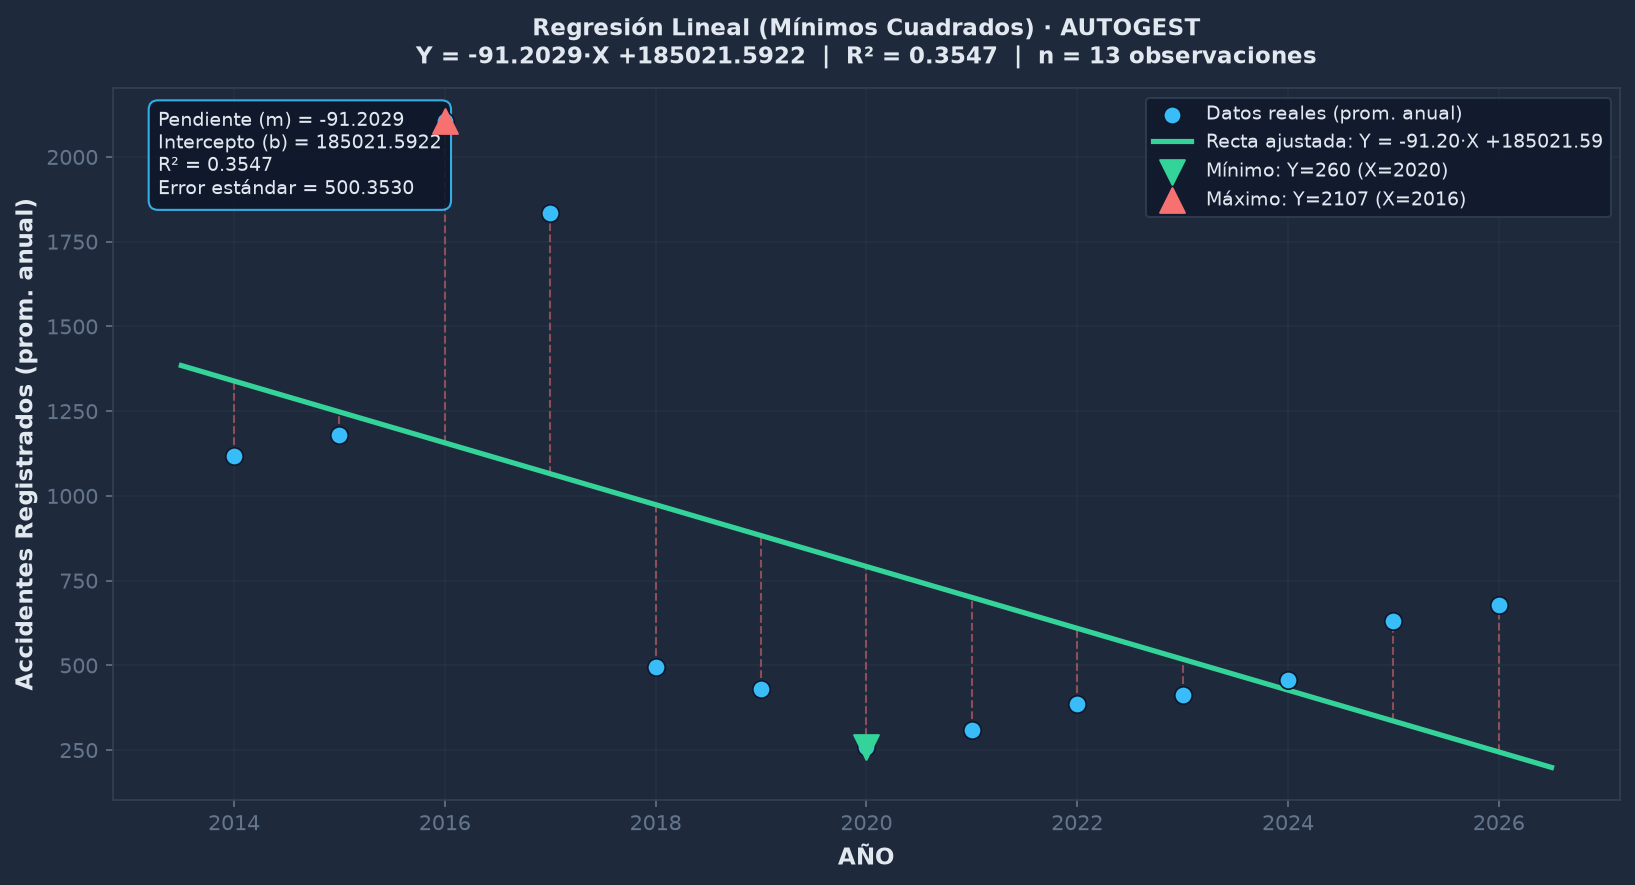


📊 INTERPOLACION LAGRANGE


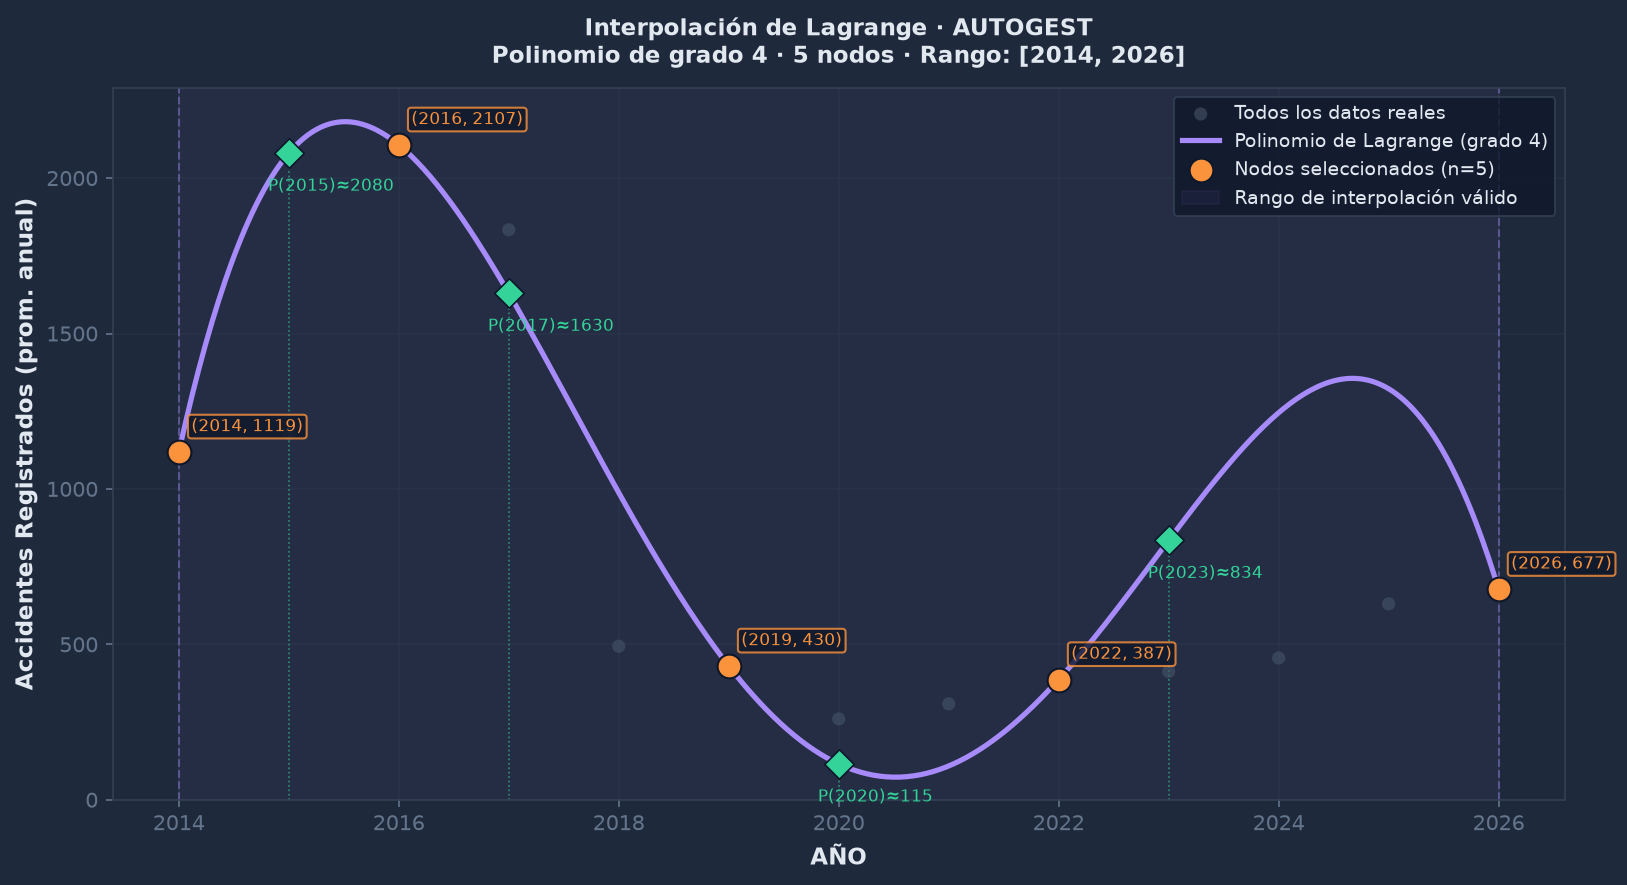


📊 PANEL COMPARATIVO


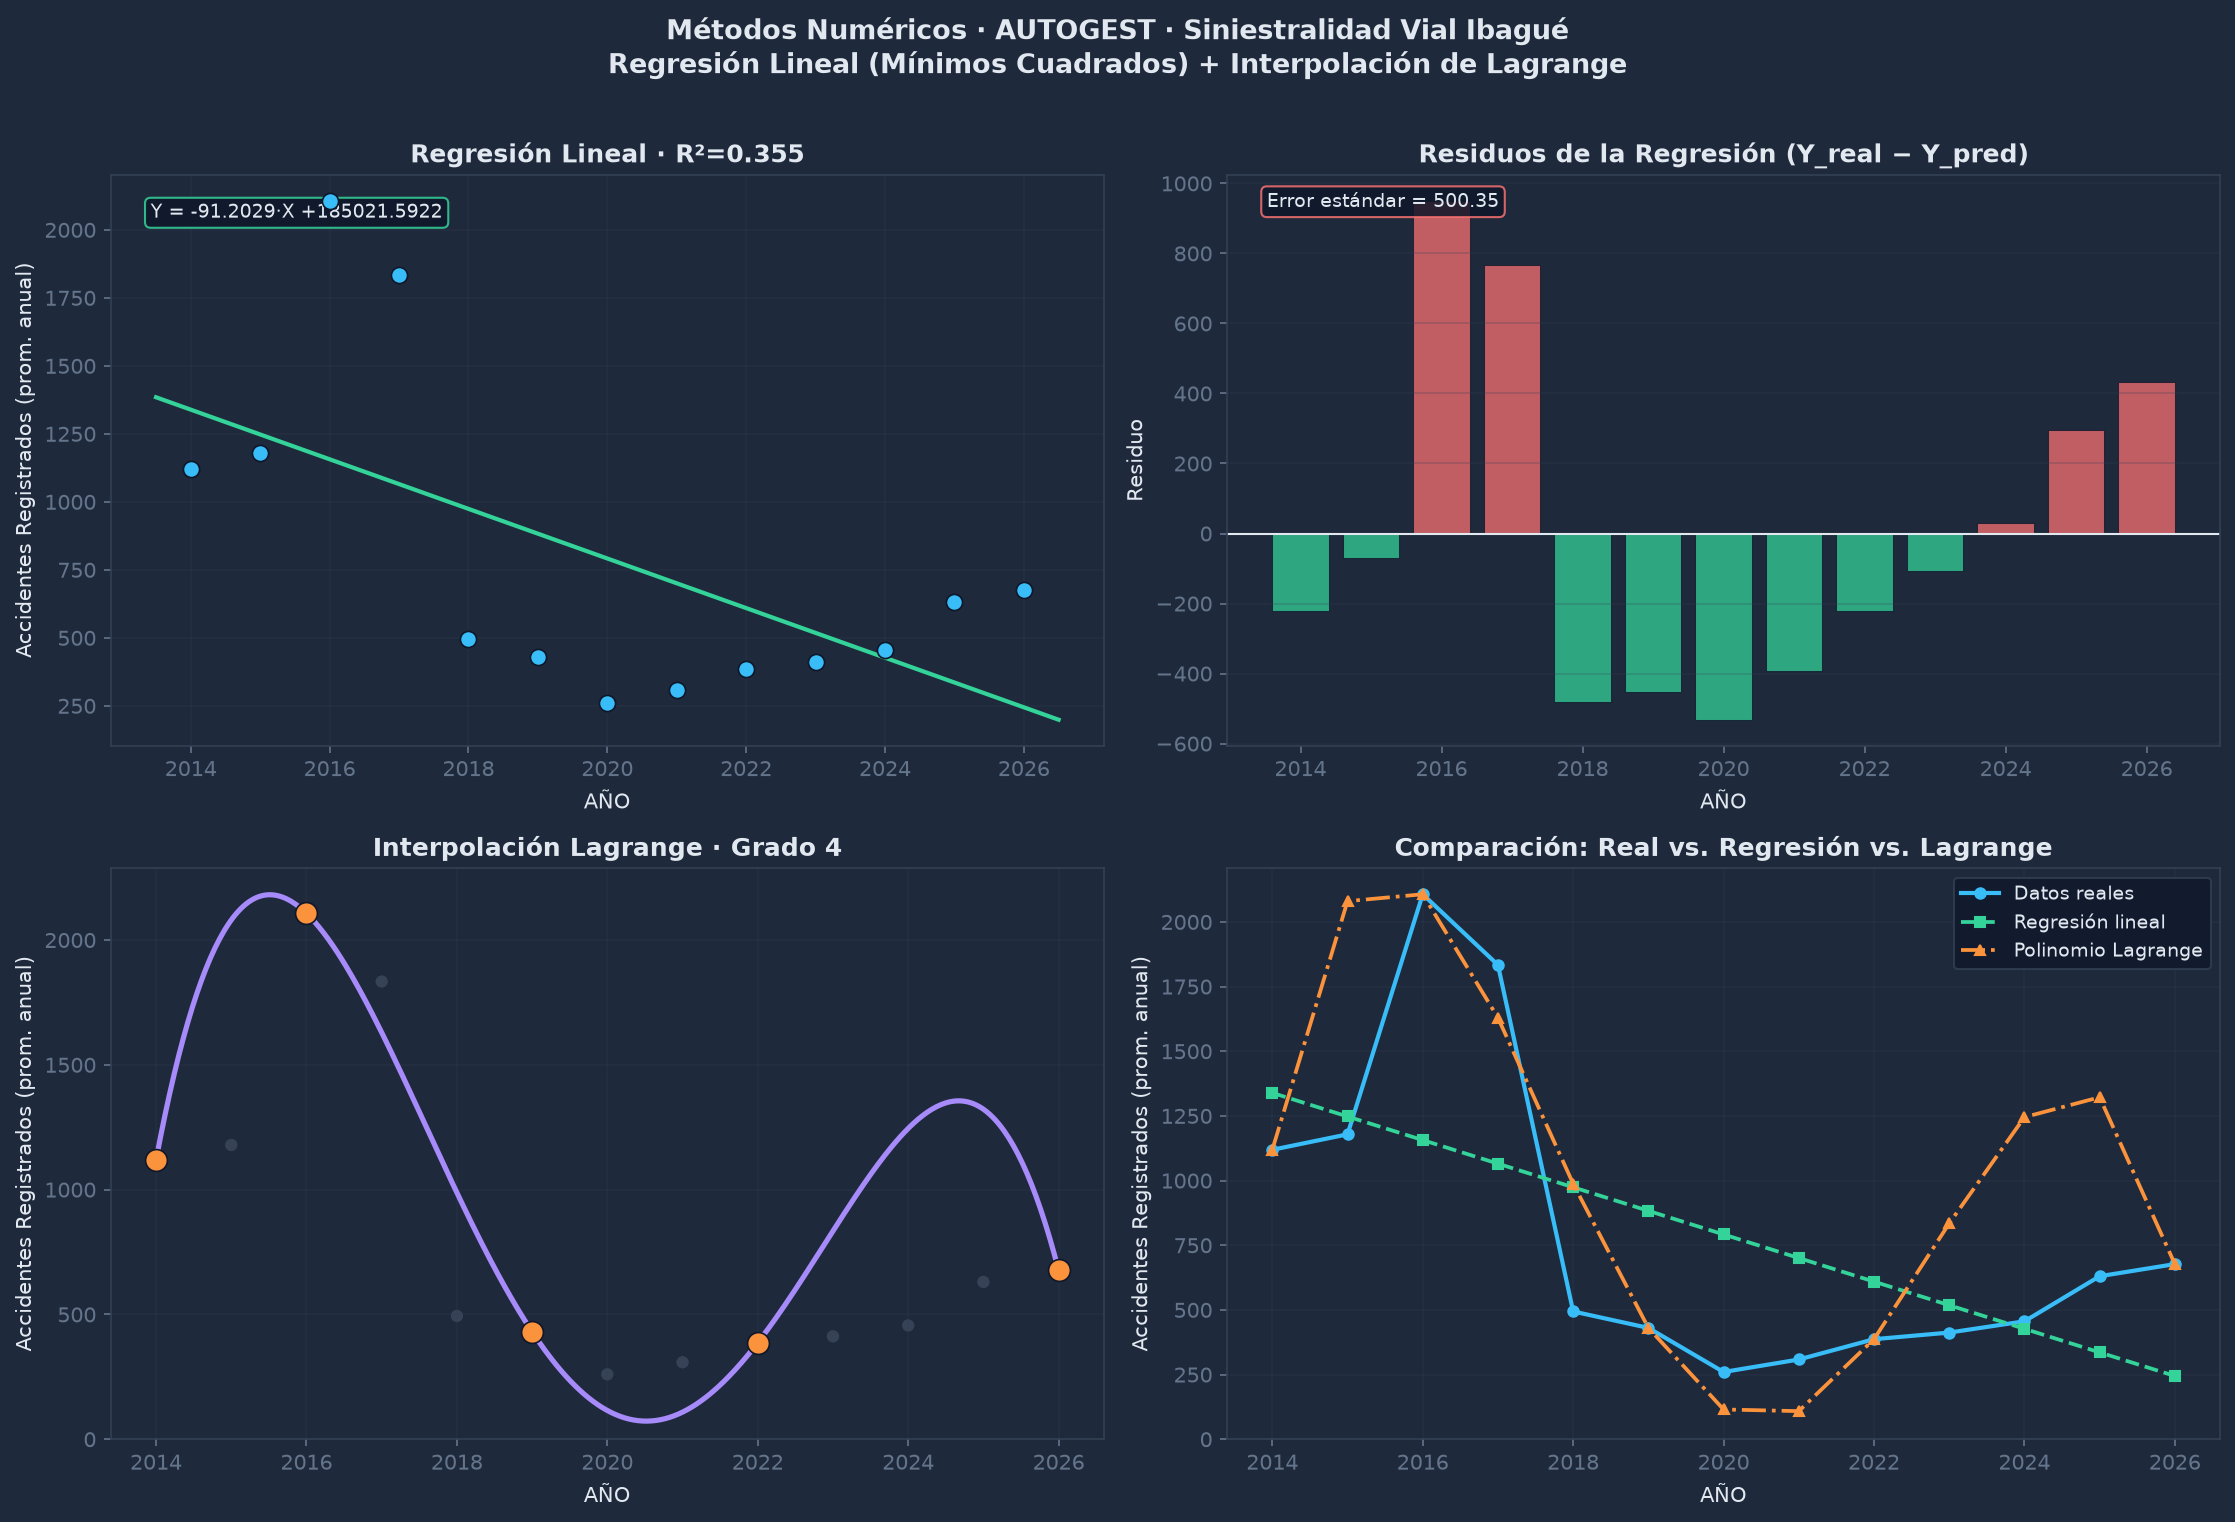

In [11]:
# Mostrar figuras inline
from IPython.display import Image, display
import os

for nombre, ruta in rutas.items():
    print(f"\n📊 {nombre.replace('_',' ').upper()}")
    display(Image(filename=ruta, width=900))

## 7. Comparación de Métodos

| Característica | Regresión Lineal | Interpolación de Lagrange |
|---|---|---|
| **Propósito** | Modelar tendencia general | Estimar valores dentro del rango |
| **Fórmula** | Y = m·X + b (recta) | P(x) = Σ yi·Li(x) (polinomio) |
| **Pasa por todos los datos** | ❌ No (minimiza error) | ✅ Sí (en los nodos) |
| **Datos usados** | 13 promedios anuales | 5 nodos estratégicos |
| **Grado** | 1 (lineal) | 4 (cuártico) |
| **Uso principal** | Predicción / tendencia | Interpolación dentro del rango |
| **Validez fuera del rango** | Extrapolación (menos confiable) | No recomendado |


In [12]:
# Tabla de comparación numérica para puntos seleccionados
print("COMPARACIÓN NUMÉRICA: Y_real vs Y_regresión vs Y_lagrange")
print("=" * 70)
print(f"{'AÑO':>6}  {'Y_real':>10}  {'Y_regresión':>12}  {'Y_lagrange':>12}  {'Err_RL%':>8}  {'Err_Lag%':>9}")
print("─" * 70)

for xi, yi in zip(X, Y):
    y_rl  = rl.predecir(xi)
    y_lag = lag.interpolar(xi)
    e_rl  = abs(yi - y_rl)  / yi * 100
    e_lag = abs(yi - y_lag) / yi * 100
    print(f"{xi:>6.0f}  {yi:>10.2f}  {y_rl:>12.2f}  {y_lag:>12.2f}  {e_rl:>7.2f}%  {e_lag:>8.2f}%")

print("─" * 70)
errs_rl  = [abs(yi - rl.predecir(xi)) / yi * 100 for xi, yi in zip(X, Y)]
errs_lag = [abs(yi - lag.interpolar(xi)) / yi * 100 for xi, yi in zip(X, Y)]
print(f"{'PROMEDIO':>35}  {sum(errs_rl)/len(errs_rl):>12.2f}%  {sum(errs_lag)/len(errs_lag):>8.2f}%")

COMPARACIÓN NUMÉRICA: Y_real vs Y_regresión vs Y_lagrange
   AÑO      Y_real   Y_regresión    Y_lagrange   Err_RL%   Err_Lag%
──────────────────────────────────────────────────────────────────────
  2014     1119.03       1339.04       1119.03    19.66%      0.00%
  2015     1178.81       1247.84       2080.30     5.86%     76.47%
  2016     2106.92       1156.63       2106.92    45.10%      0.00%
  2017     1833.67       1065.43       1629.53    41.90%     11.13%
  2018      494.06        974.23        987.79    97.19%     99.93%
  2019      430.42        883.02        430.42   105.15%      0.00%
  2020      259.98        791.82        115.13   204.57%     55.72%
  2021      308.31        700.62        108.67   127.24%     64.75%
  2022      386.83        609.42        386.83    57.54%      0.00%
  2023      412.38        518.21        834.40    25.66%    102.34%
  2024      455.94        427.01       1245.23     6.35%    173.11%
  2025      630.25        335.81       1322.15    46.72

## 8. ✅ Checklist del Profesor

| Requisito (audio del profesor) | Estado | Detalle |
|---|:---:|---|
| Elegir 2 variables cuantitativas | ✅ | AÑO (tiempo) y ACCIDENTES_REGISTRADOS |
| Definir cuál es independiente y dependiente | ✅ | X=AÑO, Y=ACCIDENTES |
| Dato mínimo y máximo incluidos | ✅ | 2014 (mínimo X) y 2026 (máximo X) |
| Calcular la pendiente | ✅ | m = Σ[(xi−x̄)(yi−ȳ)] / Σ[(xi−x̄)²] |
| Calcular el intercepto | ✅ | b = ȳ − m·x̄ |
| Ecuación de la recta | ✅ | Y = m·X + b |
| Calcular el error de la regresión | ✅ | Error abs, Error %, R², Error estándar |
| Gráfico de la regresión | ✅ | fig_regresion_lineal.png |
| Elegir 3-5 nodos para Lagrange | ✅ | 5 nodos estratégicos |
| Polinomio de Lagrange | ✅ | Grado 4 (cuártico) |
| Interpolar dentro del rango | ✅ | 7 puntos interpolados |
| Gráfico de la interpolación | ✅ | fig_interpolacion_lagrange.png |
| Paso a paso del proceso | ✅ | Este notebook + reporte() |


In [13]:
# Resumen final
print("=" * 65)
print("RESUMEN FINAL — MÉTODOS NUMÉRICOS · AUTOGEST")
print("=" * 65)
print()
print("REGRESIÓN LINEAL (Mínimos Cuadrados)")
print(f"  Ecuación:   Y = {rl.pendiente:+.4f}·X {rl.intercepto:+.4f}")
print(f"  Pendiente:  {rl.pendiente:.4f}  → accidentes varían {rl.pendiente:+.2f}/año")
print(f"  Intercepto: {rl.intercepto:.4f}")
print(f"  R²:         {rl.r2:.4f}  ({rl.r2*100:.2f}% variabilidad explicada)")
print(f"  n datos:    {len(X)}")
print()
print("INTERPOLACIÓN DE LAGRANGE")
print(f"  Nodos:      {lag.X_nodos}")
print(f"  Y en nodos: {lag.Y_nodos}")
print(f"  Grado:      {lag.grado} (cuártico)")
print(f"  Rango:      [{min(lag.X_nodos)}, {max(lag.X_nodos)}]")
print()
print("FIGURAS GENERADAS:")
for k, v in rutas.items():
    print(f"  · {k}")
print("=" * 65)

RESUMEN FINAL — MÉTODOS NUMÉRICOS · AUTOGEST

REGRESIÓN LINEAL (Mínimos Cuadrados)
  Ecuación:   Y = -91.2029·X +185021.5922
  Pendiente:  -91.2029  → accidentes varían -91.20/año
  Intercepto: 185021.5922
  R²:         0.3547  (35.47% variabilidad explicada)
  n datos:    13

INTERPOLACIÓN DE LAGRANGE
  Nodos:      [2014, 2016, 2019, 2022, 2026]
  Y en nodos: [1119.03, 2106.92, 430.42, 386.83, 677.07]
  Grado:      4 (cuártico)
  Rango:      [2014, 2026]

FIGURAS GENERADAS:
  · regresion_lineal
  · interpolacion_lagrange
  · panel_comparativo
